# MMseqs clustering curves with characterized members

Regenerates the *number of clusters vs. identity and coverage threshold* figure of
`mmseqs_curves.py` from the cluster TSVs it saved (no re-clustering), and counts for
every threshold how many clusters contain at least one characterized member. A second
figure shows how many different EC labels and how many characterized sequences those
clusters contain.

A cluster member counts as characterized when its GenBank accession (version included)
is in the `GenBank` column of `characterized_ALL.tsv`. Rows of every CAZy family are
used, because a multi-domain protein can be listed under another family than GH43.

In [11]:
import ast
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FuncFormatter

CLUSTER_DIR = Path("/Users/maartenboneschansker/Documents/PhD/projects/cazyme_deep_dive/"
                   "GH43_deep_dive/results/cluster_analysis/mmseqs_clusters")
ANNOTATION = Path("/Users/maartenboneschansker/Documents/PhD/projects/cazyme_data_collection/"
                  "2026-09-24_download/consolidated/characterized_ALL.tsv")
OUT_DIR = CLUSTER_DIR.parent  # next to mmseqs_clustering_curves.png

# Count EC labels that share an EC number as one label (partial match, as in
# blast_benchmark.py). Outputs that depend on it get a _partial suffix.
PARTIAL = True

## Characterized accessions

In [12]:
annotation = pd.read_csv(ANNOTATION, sep="\t", dtype=str, keep_default_na=False)
characterized = set(annotation["GenBank"].str.strip()) - {""}
print(f"{ANNOTATION.name}: {len(annotation):,} rows, {len(characterized):,} GenBank accessions")

characterized_ALL.tsv: 12,279 rows, 12,169 GenBank accessions


## Clusters per threshold

Each `clusters_cov<c>_id<i>.tsv` holds one `representative, member` row per sequence;
a cluster is a representative.

In [13]:
FILE_RE = re.compile(r"clusters_cov(?P<coverage>[\d.]+)_id(?P<identity>[\d.]+)\.tsv")

rows, cluster_tables = [], {}
for path in sorted(CLUSTER_DIR.glob("clusters_cov*_id*.tsv")):
    m = FILE_RE.fullmatch(path.name)
    coverage, identity = float(m["coverage"]), float(m["identity"])
    clusters = pd.read_csv(path, sep="\t", header=None, names=["representative", "member"])
    clusters["characterized"] = clusters["member"].isin(characterized)
    cluster_tables[coverage, identity] = clusters
    per_cluster = clusters.groupby("representative")["characterized"].sum()
    rows.append({
        "coverage": coverage,
        "identity": identity,
        "clusters": len(per_cluster),
        "clusters_characterized": int((per_cluster > 0).sum()),
        "members": len(clusters),
        "members_characterized": int(clusters["characterized"].sum()),
        "max_characterized_per_cluster": int(per_cluster.max()),
    })

results = pd.DataFrame(rows).sort_values(["coverage", "identity"], ignore_index=True)
results["pct_characterized"] = 100 * results["clusters_characterized"] / results["clusters"]
# Mean over the clusters with a characterized member, not over all clusters.
results["mean_characterized_per_cluster"] = (results["members_characterized"]
                                             / results["clusters_characterized"])

n_members = results["members"].iloc[0]
n_characterized = results["members_characterized"].iloc[0]
print(f"{len(results)} cluster files; {n_characterized:,} of {n_members:,} sequences are characterized")

28 cluster files; 269 of 48,078 sequences are characterized


The cluster counts should equal the ones behind the original figure (`mmseqs_clustering_results.csv`).

In [14]:
original_csv = OUT_DIR / "mmseqs_clustering_results.csv"
if original_csv.exists():
    original = (pd.read_csv(original_csv, index_col=0)
                .rename_axis(index="identity", columns="coverage")
                .stack().rename("original").reset_index()
                .astype({"coverage": float}).round({"identity": 2, "coverage": 2}))
    check = results.merge(original, on=["coverage", "identity"])
    mismatch = check[check["clusters"] != check["original"]]
    print(f"{len(check) - len(mismatch)}/{len(check)} thresholds match {original_csv.name}")
    if len(mismatch):
        display(mismatch)

28/28 thresholds match mmseqs_clustering_results.csv


## Characterized clusters per threshold

Clusters with at least one characterized member, out of all clusters.

In [15]:
table = (results
         .assign(cell=lambda d: [f"{a:,} / {n:,} ({p:.1f}%)" for a, n, p in
                                 zip(d["clusters_characterized"], d["clusters"], d["pct_characterized"])])
         .pivot(index="identity", columns="coverage", values="cell"))
table.index = [f"{i:.0%}" for i in table.index]
table.index.name = "identity"
table.columns = [f"coverage {c:.2f}" for c in table.columns]
table

,coverage 0.30,coverage 0.50,coverage 0.70,coverage 0.90
identity,,,,
30%,33 / 274 (12.0%),43 / 581 (7.4%),"69 / 1,166 (5.9%)","117 / 2,524 (4.6%)"
40%,81 / 648 (12.5%),"76 / 1,019 (7.5%)","98 / 1,581 (6.2%)","122 / 2,763 (4.4%)"
50%,"124 / 1,504 (8.2%)","119 / 1,911 (6.2%)","137 / 2,502 (5.5%)","148 / 3,524 (4.2%)"
60%,"162 / 3,497 (4.6%)","169 / 3,903 (4.3%)","175 / 4,389 (4.0%)","179 / 5,187 (3.5%)"
70%,"200 / 6,505 (3.1%)","201 / 6,889 (2.9%)","203 / 7,314 (2.8%)","202 / 7,951 (2.5%)"
80%,"234 / 10,676 (2.2%)","235 / 10,952 (2.1%)","235 / 11,228 (2.1%)","235 / 11,670 (2.0%)"
90%,"250 / 15,635 (1.6%)","250 / 15,832 (1.6%)","250 / 16,016 (1.6%)","251 / 16,296 (1.5%)"


## Figure: clusters and characterized clusters

Left: all clusters, as in `mmseqs_curves.py`. Right: the percentage of those clusters
that contain at least one characterized member. Coverage is ordered, so its lines share
one blue ramp, light (0.30) to dark (0.90).

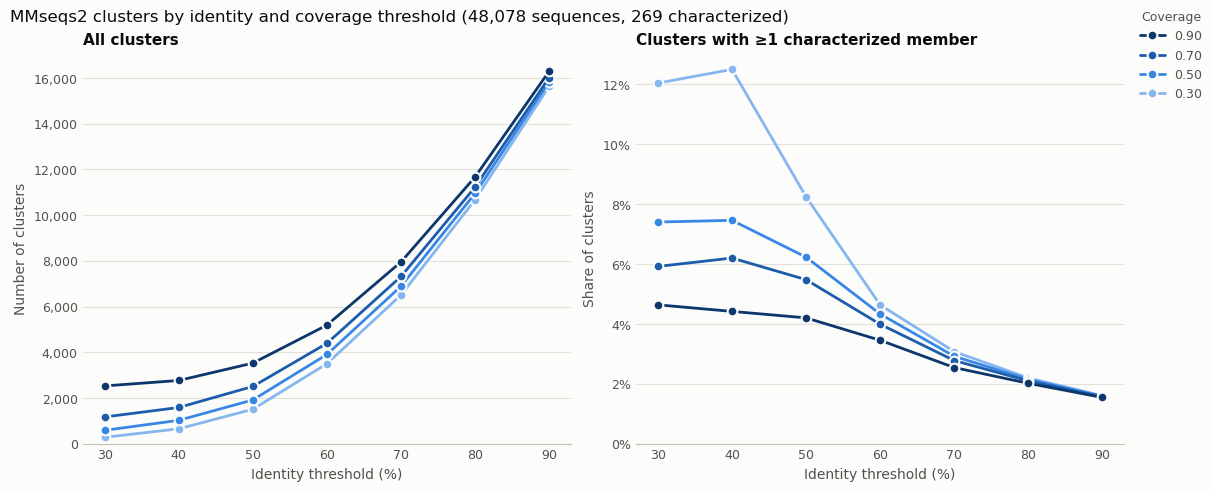

In [16]:
SURFACE, INK, INK_SECONDARY = "#fcfcfb", "#0b0b0b", "#52514e"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"
COVERAGE_COLORS = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]  # ordinal ramp, low -> high coverage

coverages = sorted(results["coverage"].unique())
colors = dict(zip(coverages, COVERAGE_COLORS))


def plot_panel(ax, data, col, title, ylabel, tick_format):
    """One line per coverage value: data[col] against the identity threshold.
    tick_format None keeps matplotlib's tick labels, whose decimals follow the range."""
    ax.set_facecolor(SURFACE)
    for cov in coverages:
        d = data[data["coverage"] == cov]
        ax.plot(d["identity"] * 100, d[col], color=colors[cov], label=f"{cov:.2f}",
                linewidth=2, solid_joinstyle="round", solid_capstyle="round",
                marker="o", markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5)
    ax.set_title(title, loc="left", fontsize=11, fontweight="semibold", color=INK)
    ax.set_xlabel("Identity threshold (%)", color=INK_SECONDARY)
    ax.set_ylabel(ylabel, color=INK_SECONDARY)
    ax.set_xticks(sorted(data["identity"].unique() * 100))
    if tick_format:
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: tick_format.format(v)))
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(BASELINE)
    ax.tick_params(length=0, labelsize=9, labelcolor=INK_SECONDARY)


def finish_figure(fig, axes, title, y_bottom=0):
    """y axes from y_bottom (set after all panels are drawn, so a shared axis fits every
    panel), coverage legend with the highest coverage on top, and the figure title."""
    for ax in axes:
        ax.set_ylim(bottom=y_bottom)
    handles, labels = axes[0].get_legend_handles_labels()
    legend = fig.legend(handles[::-1], labels[::-1], title="Coverage", loc="outside right upper",
                        frameon=False, fontsize=9, title_fontsize=9, labelcolor=INK_SECONDARY)
    legend.get_title().set_color(INK_SECONDARY)
    fig.suptitle(title, x=0.0, ha="left", fontsize=12, color=INK)


fig_counts, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained", facecolor=SURFACE)
plot_panel(axes[0], results, "clusters", "All clusters", "Number of clusters", "{:,.0f}")
plot_panel(axes[1], results, "pct_characterized", "Clusters with ≥1 characterized member",
           "Share of clusters", "{:.0f}%")
finish_figure(fig_counts, axes, f"MMseqs2 clusters by identity and coverage threshold "
                                f"({n_members:,} sequences, {n_characterized:,} characterized)")
plt.show()

## Annotated clusters: EC labels and characterized sequences

For every cluster with a characterized member, two numbers, each averaged per threshold:

- **Different EC labels** among its characterized members; 1 means they all share one
  label. A member's label is its set of complete EC numbers, so a bifunctional enzyme is
  one label (`3.2.1.37;3.2.1.55`). Wildcards such as `3.2.1.-` are dropped, as in
  `label_cv_split.py`; a member with only wildcard ECs has no label, and a cluster without
  labelled members is left out of this average.
  With `PARTIAL = True`, labels that share an EC number count as one, also through a
  chain: `3.2.1.37`, `3.2.1.37;3.2.1.55` and `3.2.1.55` are one label together.
- **Characterized sequences** in the cluster.

A cluster with a single characterized sequence has 1 EC label by definition, so where the
second number approaches 1, the first does too.

In [17]:
def complete_ecs(cell: str) -> set[str]:
    """EC numbers in an EC cell (a single EC or a list literal), without wildcards."""
    cell = cell.strip()
    ecs = ast.literal_eval(cell) if cell.startswith("[") else [cell]
    return {str(e).strip() for e in ecs if str(e).strip() and "-" not in str(e)}


def count_ec_labels(labels: pd.Series) -> int:
    """Number of different EC labels. With PARTIAL, labels that share an EC number,
    directly or through a chain of shared ECs, count as one."""
    distinct = set(labels)
    if not PARTIAL:
        return len(distinct)
    groups: list[set[str]] = []  # EC numbers of each group of overlapping labels
    for label in distinct:
        ecs = set(label.split(";"))
        for group in [g for g in groups if g & ecs]:
            groups.remove(group)
            ecs |= group
        groups.append(ecs)
    return len(groups)


ec_sets = {}
for acc, cell in zip(annotation["GenBank"].str.strip(), annotation["EC"]):
    if acc:
        ec_sets.setdefault(acc, set()).update(complete_ecs(cell))
ec_labels = {acc: ";".join(sorted(ecs)) for acc, ecs in ec_sets.items() if ecs}

label_rows = []
for (coverage, identity), clusters in cluster_tables.items():
    labelled = clusters.assign(ec=clusters["member"].map(ec_labels)).dropna(subset=["ec"])
    n_ec_labels = labelled.groupby("representative")["ec"].agg(count_ec_labels)
    label_rows.append({
        "coverage": coverage,
        "identity": identity,
        "clusters_labelled": len(n_ec_labels),
        "mean_ec_labels": n_ec_labels.mean(),
        "max_ec_labels": n_ec_labels.max(),
        "clusters_mixed": int((n_ec_labels > 1).sum()),
    })
ec_label_counts = (pd.DataFrame(label_rows)
                   .sort_values(["coverage", "identity"], ignore_index=True))

n_labelled = len(labelled)
print(f"{n_labelled} of {n_characterized} characterized sequences have a complete EC number")
print(f"PARTIAL = {PARTIAL}: labels sharing an EC number count as "
      f"{'one' if PARTIAL else 'different'}")

243 of 269 characterized sequences have a complete EC number
PARTIAL = True: labels sharing an EC number count as one


Mean per cluster at each threshold, with the highest value in any one cluster and the
number of clusters averaged over.

In [18]:
def threshold_table(data, mean_col, max_col, n_col):
    t = (data
         .assign(cell=lambda d: [f"{mean:.2f} (max {mx}, n={n})" for mean, mx, n in
                                 zip(d[mean_col], d[max_col], d[n_col])])
         .pivot(index="identity", columns="coverage", values="cell"))
    t.index = [f"{i:.0%}" for i in t.index]
    t.index.name = "identity"
    t.columns = [f"coverage {c:.2f}" for c in t.columns]
    return t


print("Different EC labels per cluster (clusters with an EC-labelled member)")
display(threshold_table(ec_label_counts, "mean_ec_labels", "max_ec_labels", "clusters_labelled"))
print("Characterized sequences per cluster (clusters with a characterized member)")
display(threshold_table(results, "mean_characterized_per_cluster",
                        "max_characterized_per_cluster", "clusters_characterized"))

Different EC labels per cluster (clusters with an EC-labelled member)


,coverage 0.30,coverage 0.50,coverage 0.70,coverage 0.90
identity,,,,
30%,"1.20 (max 2, n=30)","1.18 (max 3, n=39)","1.15 (max 2, n=62)","1.07 (max 2, n=103)"
40%,"1.11 (max 2, n=74)","1.11 (max 2, n=71)","1.10 (max 2, n=89)","1.05 (max 2, n=110)"
50%,"1.06 (max 2, n=113)","1.06 (max 2, n=110)","1.03 (max 2, n=127)","1.02 (max 2, n=134)"
60%,"1.03 (max 2, n=143)","1.03 (max 2, n=149)","1.02 (max 2, n=155)","1.01 (max 2, n=159)"
70%,"1.01 (max 2, n=178)","1.01 (max 2, n=179)","1.01 (max 2, n=181)","1.01 (max 2, n=180)"
80%,"1.00 (max 2, n=209)","1.00 (max 2, n=210)","1.00 (max 2, n=210)","1.00 (max 2, n=210)"
90%,"1.00 (max 2, n=225)","1.00 (max 2, n=225)","1.00 (max 2, n=225)","1.00 (max 2, n=226)"


Characterized sequences per cluster (clusters with a characterized member)


,coverage 0.30,coverage 0.50,coverage 0.70,coverage 0.90
identity,,,,
30%,"8.15 (max 50, n=33)","6.26 (max 59, n=43)","3.90 (max 48, n=69)","2.30 (max 30, n=117)"
40%,"3.32 (max 31, n=81)","3.54 (max 35, n=76)","2.74 (max 30, n=98)","2.20 (max 29, n=122)"
50%,"2.17 (max 23, n=124)","2.26 (max 30, n=119)","1.96 (max 29, n=137)","1.82 (max 27, n=148)"
60%,"1.66 (max 11, n=162)","1.59 (max 11, n=169)","1.54 (max 11, n=175)","1.50 (max 11, n=179)"
70%,"1.34 (max 8, n=200)","1.34 (max 8, n=201)","1.33 (max 8, n=203)","1.33 (max 8, n=202)"
80%,"1.15 (max 3, n=234)","1.14 (max 3, n=235)","1.14 (max 3, n=235)","1.14 (max 3, n=235)"
90%,"1.08 (max 3, n=250)","1.08 (max 3, n=250)","1.08 (max 3, n=250)","1.07 (max 3, n=251)"


## Figure: annotated clusters

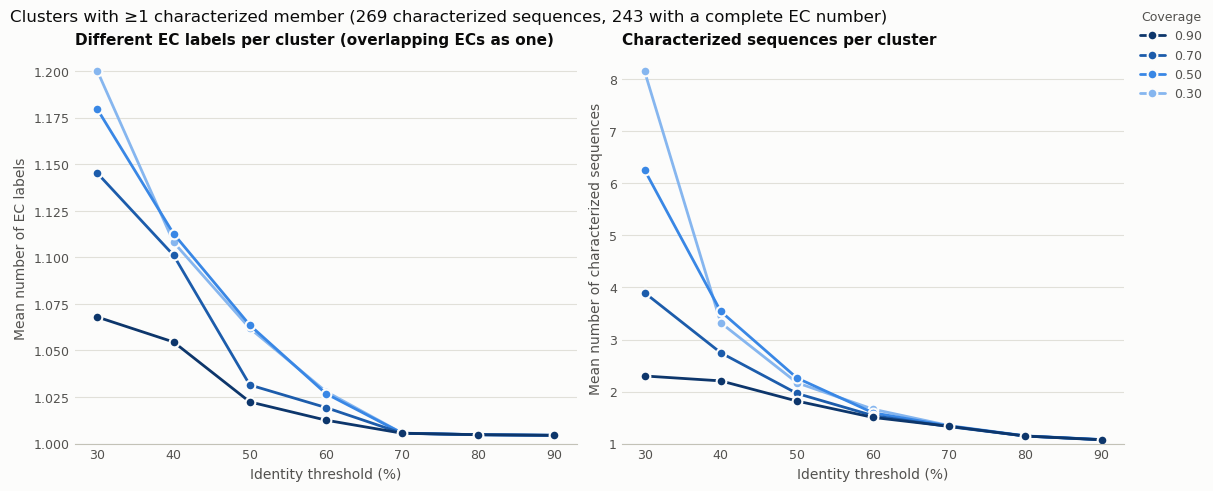

In [19]:
fig_annotated, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained",
                                   facecolor=SURFACE)
plot_panel(axes[0], ec_label_counts, "mean_ec_labels",
           "Different EC labels per cluster" + (" (overlapping ECs as one)" if PARTIAL else ""),
           "Mean number of EC labels", None)
plot_panel(axes[1], results, "mean_characterized_per_cluster",
           "Characterized sequences per cluster", "Mean number of characterized sequences",
           "{:.0f}")
# An annotated cluster has at least 1 of both, so the axes start there.
finish_figure(fig_annotated, axes, f"Clusters with ≥1 characterized member "
                                   f"({n_characterized} characterized sequences, "
                                   f"{n_labelled} with a complete EC number)", y_bottom=1)
plt.show()

## Save

In [20]:
suffix = "_partial" if PARTIAL else ""
figure_paths = {fig_counts: OUT_DIR / "mmseqs_clustering_curves_characterized.png",
                fig_annotated: OUT_DIR / f"mmseqs_clustering_annotated_clusters{suffix}.png"}
csv_path = OUT_DIR / f"mmseqs_clustering_characterized{suffix}.csv"
for fig, path in figure_paths.items():
    fig.savefig(path, dpi=300, bbox_inches="tight", facecolor=SURFACE)
    print(f"Figure saved to {path}")
results.merge(ec_label_counts, on=["coverage", "identity"]).to_csv(csv_path, index=False)
print(f"Table saved to {csv_path}")

Figure saved to /Users/maartenboneschansker/Documents/PhD/projects/cazyme_deep_dive/GH43_deep_dive/results/cluster_analysis/mmseqs_clustering_curves_characterized.png
Figure saved to /Users/maartenboneschansker/Documents/PhD/projects/cazyme_deep_dive/GH43_deep_dive/results/cluster_analysis/mmseqs_clustering_annotated_clusters_partial.png
Table saved to /Users/maartenboneschansker/Documents/PhD/projects/cazyme_deep_dive/GH43_deep_dive/results/cluster_analysis/mmseqs_clustering_characterized_partial.csv
